In [1]:
import torch

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device", device)

Using device cpu


In [2]:
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307), (0.3081))
])
full_train_dataset = datasets.MNIST(
    root = "data",
    train =True,
    download = True,
    transform = transform
)
test_dataset = datasets.MNIST(
    root = "data",
    train = False,
    download = True,
    transform = transform
)

print("Training Samples:", len(full_train_dataset))
print("Test Samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 403kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.90MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.32MB/s]

Training Samples: 60000
Test Samples: 10000


In [3]:
image, label = full_train_dataset[0]

print("Image Shape:", image.shape)
print("Image dtype:", image.dtype)
print("Label:", label)

Image Shape: torch.Size([1, 28, 28])
Image dtype: torch.float32
Label: 5


In [4]:
from torch.utils.data import random_split

SEED = 42

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [50_000, 10_000],
    generator = torch.Generator().manual_seed(SEED)
)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 50000
Val: 10000
Test: 10000


In [5]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = BATCH_SIZE,
    shuffle =True
)

test_loader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle =True
    
)


images, labels = next(iter(train_loader))



print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Images dtype: torch.float32
Labels dtype: torch.int64


In [6]:
import torch.nn as nn

class MNISTANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

torch.manual_seed(SEED)
model  = MNISTANN().to(device)
print(model)

MNISTANN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


In [7]:
with torch.inference_mode():
    logits = model(images.to(device))

print("Inputs shape:", images.shape)
print("Output shape:", logits.shape)

Inputs shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [8]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

LEARNING_RATE = 0.001
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [9]:
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = 100 * total_correct / total_samples

    return average_loss, accuracy

In [10]:
EPOCHS = 5 
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    total_train_samples = 0
    
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        
        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        total_train_samples += batch_size

    # ---> EVERYTHING BELOW MUST BE INDENTED INSIDE THE EPOCH LOOP <---
    train_loss = running_loss / total_train_samples  # Fixed typo: running_loss
    val_loss, val_accuracy = evaluate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch 1/5 | Train Loss: 0.2886 | Val Loss: 0.1659 | Val Accuracy: 94.93%
Epoch 2/5 | Train Loss: 0.1231 | Val Loss: 0.1283 | Val Accuracy: 96.13%
Epoch 3/5 | Train Loss: 0.0852 | Val Loss: 0.1113 | Val Accuracy: 96.64%
Epoch 4/5 | Train Loss: 0.0672 | Val Loss: 0.0996 | Val Accuracy: 97.10%
Epoch 5/5 | Train Loss: 0.0531 | Val Loss: 0.1028 | Val Accuracy: 96.94%


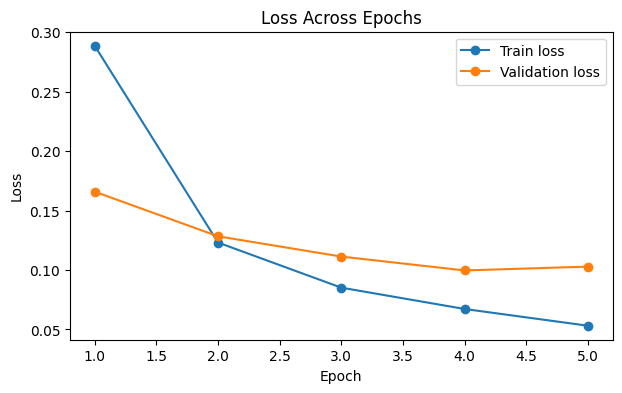

In [11]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, marker="o", label="Train loss")
plt.plot(epochs, val_losses, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Across Epochs")
plt.legend()
plt.show()

In [12]:
test_loss, test_accuracy = evaluate(model, test_loader)


print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss    : 0.0882
Test Accuracy: 97.35%


In [13]:
all_images = []
all_labels = []
all_predictions = []

model.eval()

with torch.inference_mode():
    for images, labels in test_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        all_images.append(images)
        all_labels.append(labels)
        all_predictions.append(predictions)

all_images = torch.cat(all_images)
all_labels = torch.cat(all_labels)
all_predictions = torch.cat(all_predictions)

print("Test examples             :", len(all_labels))
print("Correct predictions       :", (all_predictions == all_labels).sum().item())
print("Misclassified predictions :", (all_predictions != all_labels).sum().item())

Test examples             : 10000
Correct predictions       : 9735
Misclassified predictions : 265


In [14]:
correct_indices = torch.where(all_predictions == all_labels)[0]
wrong_indices = torch.where(all_predictions != all_labels)[0]

generator = torch.Generator().manual_seed(42)

correct_sample = correct_indices[
    torch.randperm(len(correct_indices), generator=generator)[:5]
]

wrong_sample = wrong_indices[
    torch.randperm(len(wrong_indices), generator=generator)[:5]
]

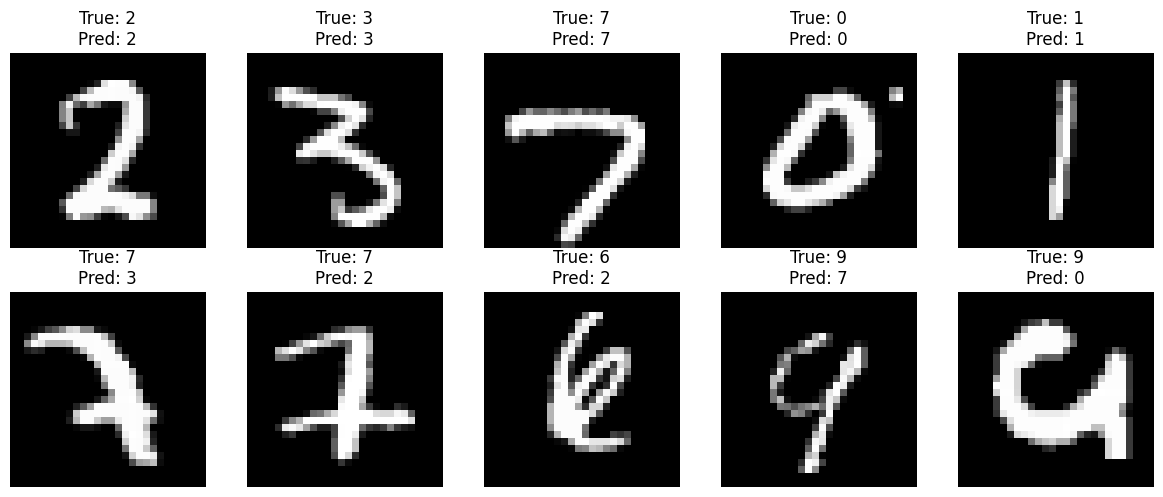

In [15]:
MNIST_MEAN = 0.1307
MNIST_STD = 0.3081

def show_image(image):
    image = image * MNIST_STD + MNIST_MEAN
    return image.squeeze().clamp(0, 1)





fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, idx in enumerate(correct_sample):
    axes[0, i].imshow(show_image(all_images[idx]), cmap="gray")
    axes[0, i].set_title(
        f"True: {all_labels[idx].item()}\n"
        f"Pred: {all_predictions[idx].item()}"
    )
    axes[0, i].axis("off")

for i, idx in enumerate(wrong_sample):
    axes[1, i].imshow(show_image(all_images[idx]), cmap="gray")
    axes[1, i].set_title(
        f"True: {all_labels[idx].item()}\n"
        f"Pred: {all_predictions[idx].item()}"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Correct", fontsize=12)
axes[1, 0].set_ylabel("Misclassified", fontsize=12)

plt.tight_layout()
plt.show()